In [1]:
import random
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.examples.tutorials.mnist import input_data

tf.set_random_seed(777)

In [2]:
mnist = input_data.read_data_sets("MNIST_data/", one_hot=True)

nb_classes = 10

Extracting MNIST_data/train-images-idx3-ubyte.gz
Extracting MNIST_data/train-labels-idx1-ubyte.gz
Extracting MNIST_data/t10k-images-idx3-ubyte.gz
Extracting MNIST_data/t10k-labels-idx1-ubyte.gz


In [3]:
X = tf.placeholder(tf.float32, [None, 784])
Y = tf.placeholder(tf.float32, [None, nb_classes])

W = tf.Variable(tf.random_normal([784, nb_classes]))
b = tf.Variable(tf.random_normal([nb_classes]))

hypothesis = tf.nn.softmax(tf.matmul(X, W) + b)

cost = tf.reduce_mean(- tf.reduce_sum(Y * tf.log(hypothesis), axis = 1))

optimizer = tf.train.GradientDescentOptimizer(learning_rate = 0.1).minimize(cost)

is_correct = tf.equal(tf.arg_max(hypothesis, 1), tf.arg_max(Y, 1))

accuracy = tf.reduce_mean(tf.cast(is_correct, tf.float32))

Epoch: 0001,  cost = 2.827615568
Epoch: 0002,  cost = 1.061945811
Epoch: 0003,  cost = 0.838052173
Epoch: 0004,  cost = 0.733724222
Epoch: 0005,  cost = 0.669940257
Epoch: 0006,  cost = 0.625172842
Epoch: 0007,  cost = 0.590443073
Epoch: 0008,  cost = 0.564010332
Epoch: 0009,  cost = 0.541215308
Epoch: 0010,  cost = 0.522697132
Epoch: 0011,  cost = 0.506362972
Epoch: 0012,  cost = 0.492164008
Epoch: 0013,  cost = 0.479868423
Epoch: 0014,  cost = 0.468790772
Epoch: 0015,  cost = 0.458836066
Learning finished
Accuracy: 0.8968
Label:  [1]
Prediction:  [1]


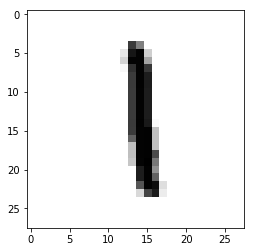

In [4]:
training_epochs = 15
batch_size = 100

with tf.Session() as sess:
    sess.run(tf.global_variables_initializer())
    
    for epoch in range(training_epochs):
        avg_cost = 0
        total_batch = int(mnist.train.num_examples / batch_size)
        
        for i in range(total_batch):
            batch_xs, batch_ys = mnist.train.next_batch(batch_size)
            c, _ = sess.run([cost, optimizer], feed_dict = {X: batch_xs, Y: batch_ys})
            avg_cost += c / total_batch
            
        print("Epoch: {:04},  cost = {:.9f}".format(epoch + 1, avg_cost))
    
    print("Learning finished")
    
    print("Accuracy:", sess.run(accuracy, feed_dict = {X: mnist.test.images, 
                                                       Y: mnist.test.labels}))
    
    # Get one and predict
    r = random.randint(0, mnist.test.num_examples - 1)
    print("Label: ", sess.run(tf.argmax(mnist.test.labels[r:r + 1], 1)))
    print("Prediction: ", sess.run(tf.argmax(hypothesis, 1), 
                                   feed_dict={X: mnist.test.images[r:r + 1]}))
    
    plt.imshow(mnist.test.images[r:r + 1].reshape(28, 28), 
               cmap = "Greys", 
               interpolation = "nearest")
    plt.show()